# Baseline + background-removal experiment (full HICMA dataset)

## 1) Fetching Data from Google Drive and Unzipping

In [ ]:
import os

# List all files in MyDrive to check for name or extension issues
drive_path = "/content/drive/MyDrive"
if os.path.exists(drive_path):
    files = os.listdir(drive_path)
    print("Files found in My Drive matching 'dataset':")
    found_any = False
    for f in files:
        if "dataset" in f.lower():
            print(f"- Name: {repr(f)} | Path: {os.path.join(drive_path, f)}")
            found_any = True
    if not found_any:
        print("No files containing the word 'dataset' were found.")
else:
    print("Google Drive is not mounted yet. Please run the mount cell first.")

Files found in My Drive matching 'dataset':
- Name: 'Qayyaf DataSet.gsheet' | Path: /content/drive/MyDrive/Qayyaf DataSet.gsheet
- Name: 'dataset (1).gsheet' | Path: /content/drive/MyDrive/dataset (1).gsheet
- Name: 'dataset.gsheet' | Path: /content/drive/MyDrive/dataset.gsheet
- Name: 'Copy of dataset.zip' | Path: /content/drive/MyDrive/Copy of dataset.zip
- Name: 'dataset.zip' | Path: /content/drive/MyDrive/dataset.zip


In [ ]:
for f in sorted(glob.glob("HICMA/**/Set*/labels*", recursive=True)):
    print("=====", f)
    print(open(f, encoding="utf-8-sig", errors="ignore").read()[:400])

===== HICMA/Full_Dataset/Set1/labels.csv
,img_name,class,label
0,012-Al-Baqara-2-156-Thuluth_segment_no_0.jpg,Thuluth,انا لله وانا اليه راجعون
1,013-3-Al-Imran-37-Thuluth_segment_no_0.jpg,Thuluth,كلما دخل عليها زكريا المحراب وجد عندها رزقا
2,013-3-Al-Imran-37-Thuluth_segment_no_1.jpg,Thuluth,قال يا مريم أن لك هذا قالت هو من عند الله إن الله يرزق من يشاء بغير حساب
3,02-Al-Fath-48-1to4-ThuluthNaskh-2_segment_no_0.jpg,Thuluth,بسم الله الرحم
===== HICMA/Full_Dataset/Set2/labels.csv
,img_name,class,label
0,657-3.jpg,Naskh,وقالوا لو كنا نسمع أو نعقل ما كنا في أصحاب
1,653-3.jpg,Naskh,وكان عاقبة أمرها خسرا أعد الله لهم عذابا شديدا
2,657-2.jpg,Naskh,وقلنا ما نزل الله من شيء إن أنتم إلا في ضلال كبير
3,655-2.jpg,Naskh,المصير إذا ألقوا فيها سمعوا لها شهيقا وهي تفور
4,659-1.jpg,Naskh,ألا يعلم من خلق وهو اللطيف الخبير هو الذي جعل
5,654-3.jpg,Naskh,وجعلناها رجوما للشياطين وأعتدنا لهم ع
===== HICMA/Full_Dataset/Set3/labels.csv
,img_name,class,label
0,489-2.jpg,Naskh,الجليل الاجل الكبير الاكبر العظيم ا

## 2) Configuration and Reading Data

In [ ]:
import random, copy, time
import numpy as np, pandas as pd, cv2
import matplotlib.pyplot as plt
from PIL import Image
from sklearn.model_selection import train_test_split

SEEDS = [42, 43, 44, 45, 46]
N_PER_CLASS = None
EPOCHS, BATCH, LR = 30, 32, 1e-4
H, W = 128, 768
STYLES = ["Naskh", "Thuluth", "Diwani", "Kufic", "Muhaquaq"]
LABELS = list(range(len(STYLES)))
IMG_EXT = (".jpg", ".jpeg", ".png")
ALT = {"Naskh": ["naskh", "naskhi"], "Thuluth": ["thuluth", "thulth"],
       "Diwani": ["diwani", "divani"], "Kufic": ["kufic", "kufi"],
       "Muhaquaq": ["muhaquaq", "muhaqqaq", "muhaqaq", "mohaqaq", "muhaqiq"]}

def norm_style(v):
    v = str(v).strip().lower()
    for k, alts in ALT.items():
        if v in alts:
            return k
    return None

def list_images(d):
    return [f for f in glob.glob(d + "/**/*", recursive=True)
            if f.lower().endswith(IMG_EXT)
            and not os.path.basename(f).startswith("._") and "__MACOSX" not in f]

def read_set(s):
    dirs = [p for p in glob.glob(f"HICMA/**/{s}", recursive=True)
            if os.path.isdir(p) and "__MACOSX" not in p]
    assert dirs, f"Could not find folder {s}"
    d = dirs[0]
    imgs = list_images(d)
    by_name = {os.path.basename(p): p for p in imgs}
    by_stem = {os.path.splitext(os.path.basename(p))[0]: p for p in imgs}
    def match(v):
        v = str(v).strip()
        return by_name.get(v) or by_stem.get(os.path.splitext(v)[0])
    lab = [f for f in glob.glob(d + "/labels*") if os.path.isfile(f)]
    assert lab, f"Could not find labels file in {s}"
    found = None
    for sep in ("\t", ",", ";", "|"):
        try:
            df = pd.read_csv(lab[0], sep=sep, dtype=str, header=None,
                             on_bad_lines="skip", encoding="utf-8-sig")
        except Exception:
            continue
        if df.shape[1] < 2:
            continue
        f_col = max(df.columns, key=lambda c: df[c].map(match).notna().mean())
        s_col = max(df.columns, key=lambda c: df[c].map(norm_style).notna().mean())
        if (df[f_col].map(match).notna().mean() > 0.5
                and df[s_col].map(norm_style).notna().mean() > 0.5):
            found = (df, f_col, s_col)
            break
    if not found:
        print(open(lab[0], encoding="utf-8-sig", errors="ignore").read()[:600])
        raise ValueError(f"Could not read file {s}")
    df, f_col, s_col = found
    rows = []
    for fn, st in zip(df[f_col], df[s_col]):
        p, y = match(fn), norm_style(st)
        if p and y:
            rows.append((s, p, y))
    print(f"{s}: {len(imgs)} images, {len(rows)} labelled rows")
    return pd.DataFrame(rows, columns=["set", "path", "style"])

allrows = pd.concat([read_set(s) for s in ["Set1", "Set2", "Set3"]], ignore_index=True)
nstyle = allrows.groupby("path")["style"].nunique()
conflicts = nstyle[nstyle > 1].index
allrows = allrows[~allrows["path"].isin(conflicts)].drop_duplicates("path").reset_index(drop=True)
print("conflicting-label images dropped:", len(conflicts), "| total images:", len(allrows))
print(allrows["style"].value_counts())

Set1: 1603 images, 1598 labelled rows
Set2: 1480 images, 1480 labelled rows
Set3: 1960 images, 1954 labelled rows
conflicting-label images dropped: 3 | total images: 5026
style
Naskh       3732
Thuluth     1007
Diwani       243
Kufic         27
Muhaquaq      17
Name: count, dtype: int64


## 3) Helper Functions: Sampling, Splitting, and Image Versions

seed 42 | sample: 5026 | train/val/test = 4020 503 503
split     test  train  val
style                     
Diwani      24    194   25
Kufic        3     22    2
Muhaquaq     1     14    2
Naskh      374   2985  373
Thuluth    101    805  101


/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1047: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


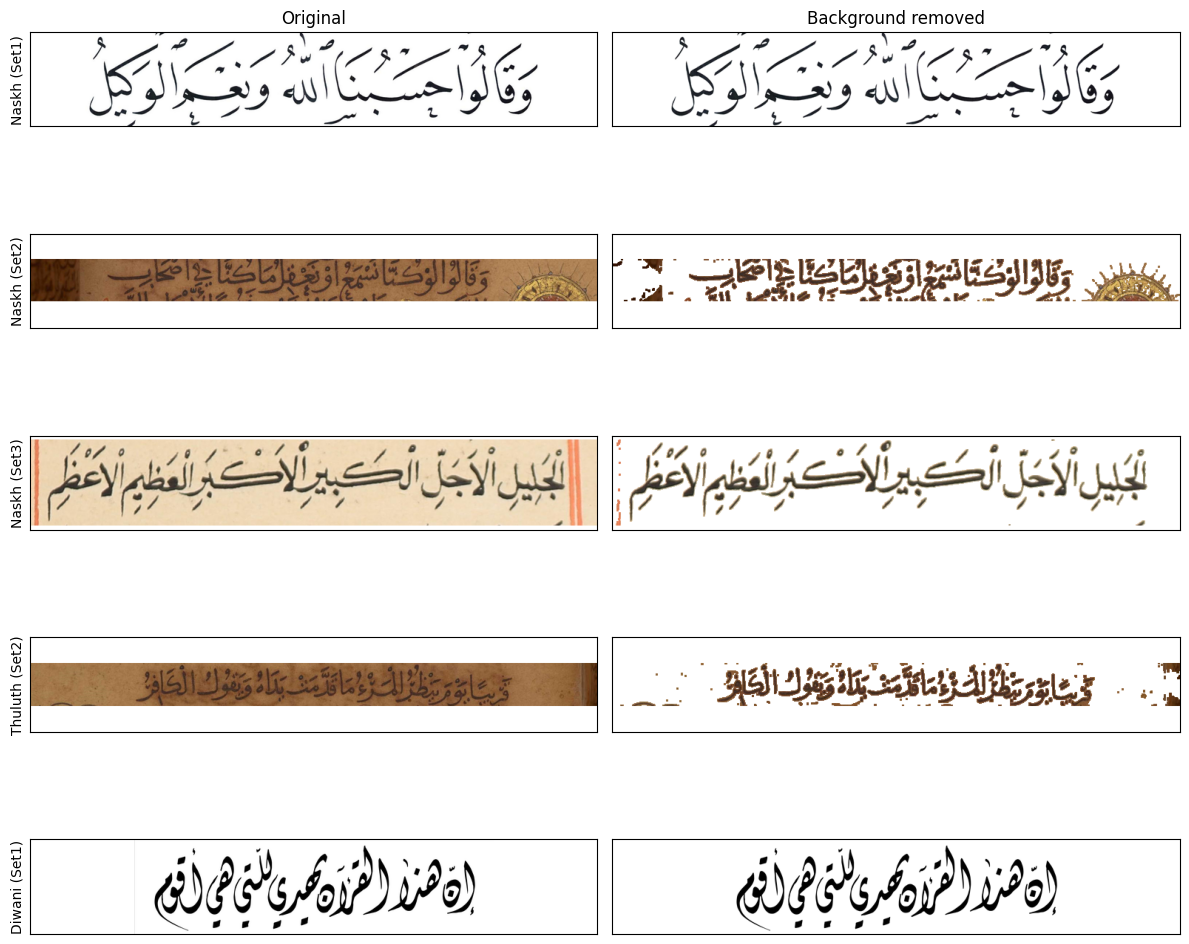

In [ ]:
def make_split(seed):
    parts = [g if N_PER_CLASS is None else g.sample(min(len(g), N_PER_CLASS), random_state=seed)
             for _, g in allrows.groupby("style")]
    sample = pd.concat(parts).reset_index(drop=True)
    sample["y"] = sample["style"].map({s: i for i, s in enumerate(STYLES)})
    ys = sample["y"].values
    idx = np.arange(len(sample))
    tr, tmp = train_test_split(idx, test_size=0.2, stratify=ys, random_state=seed)
    va, te = train_test_split(tmp, test_size=0.5, stratify=ys[tmp], random_state=seed)
    sample["split"] = "train"
    sample.loc[va, "split"] = "val"
    sample.loc[te, "split"] = "test"
    return sample, ys, tr, va, te

def fit(path):
    im = Image.open(path).convert("RGB")
    r = min(W / im.width, H / im.height)
    im = im.resize((max(1, int(im.width * r)), max(1, int(im.height * r))), Image.LANCZOS)
    canvas = Image.new("RGB", (W, H), (255, 255, 255))
    canvas.paste(im, ((W - im.width) // 2, (H - im.height) // 2))
    return canvas

def remove_bg(pil):
    img = np.array(pil)
    gray = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)
    bg = cv2.medianBlur(gray, 51)
    diff = cv2.absdiff(gray, bg)
    _, mask = cv2.threshold(diff, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    mask = cv2.dilate(mask, np.ones((3, 3), np.uint8))
    out = np.full_like(img, 255)
    out[mask > 0] = img[mask > 0]
    return Image.fromarray(out)

_cache = {}
def get_imgs(paths):
    for p in paths:
        if p not in _cache:
            f = fit(p)
            _cache[p] = (f, remove_bg(f))
    return [_cache[p][0] for p in paths], [_cache[p][1] for p in paths]

sample, ys, tr, va, te = make_split(SEEDS[0])
print("seed", SEEDS[0], "| sample:", len(sample), "| train/val/test =", len(tr), len(va), len(te))
print(pd.crosstab(sample["style"], sample["split"]))

# Get images from the entire sample
fitted, nobg = get_imgs(sample["path"].tolist())

# We will explicitly preview examples from Set1, Set2, and Set3
preview_configs = [
    {"style": "Naskh", "set": "Set1", "descr": "Set1 non-white bg"},
    {"style": "Naskh", "set": "Set2", "descr": "Set2"},
    {"style": "Naskh", "set": "Set3", "descr": "Set3"},
    {"style": "Thuluth", "set": "Set2", "descr": "Set2 non-white bg"},
    {"style": "Diwani", "set": "Set1", "descr": "Set1 non-white bg"}
]

fig, ax = plt.subplots(len(preview_configs), 2, figsize=(12, 11))
for r, cfg in enumerate(preview_configs):
    st, target_set = cfg["style"], cfg["set"]
    # Filter candidates for this style and set
    candidates = sample[(sample["style"] == st) & (sample["set"] == target_set)].index.tolist()

    # Try to find a candidate with a background (not plain white) first
    best_i = None
    if candidates:
        for i in candidates:
            if has_background(fitted[i]):
                best_i = i
                break
        if best_i is None:
            best_i = candidates[0]
    else:
        # Fallback to any available if the style/set combo is missing
        best_i = sample.index[sample["style"] == st][0]

    ax[r, 0].imshow(fitted[best_i]); ax[r, 1].imshow(nobg[best_i])
    origin_set = sample.loc[best_i, "set"]
    ax[r, 0].set_ylabel(f"{st} ({origin_set})")
    for a in ax[r]:
        a.set_xticks([]); a.set_yticks([])

ax[0, 0].set_title("Original"); ax[0, 1].set_title("Background removed")
plt.tight_layout(); plt.savefig("bg_removal_preview.png", dpi=150); plt.show()

## 4) Training Definition

In [ ]:
import torch, torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import models, transforms
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, classification_report, ConfusionMatrixDisplay

device = "cuda" if torch.cuda.is_available() else "cpu"
HARDWARE = torch.cuda.get_device_name(0) if device == "cuda" else "CPU"
print("device:", device, "|", HARDWARE)

def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

norm = transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
tf_train = transforms.Compose([transforms.RandomRotation(5, fill=(255, 255, 255)),
                               transforms.ToTensor(), norm])
tf_eval = transforms.Compose([transforms.ToTensor(), norm])

class DS(Dataset):
    def __init__(self, imgs, ys, tf): self.imgs, self.ys, self.tf = imgs, ys, tf
    def __len__(self): return len(self.imgs)
    def __getitem__(self, i): return self.tf(self.imgs[i]), int(self.ys[i])

def make_loader(imgs, ys, ids, tf, shuffle, seed):
    g = torch.Generator().manual_seed(seed)
    return DataLoader(DS([imgs[i] for i in ids], ys[ids], tf), batch_size=BATCH,
                      shuffle=shuffle, generator=g, num_workers=0)

def predict(model, dl):
    model.eval(); P, T = [], []
    with torch.no_grad():
        for xb, yb in dl:
            P += model(xb.to(device)).argmax(1).cpu().tolist(); T += yb.tolist()
    return np.array(P), np.array(T)

def macro_f1(t, p):
    return f1_score(t, p, average="macro", labels=LABELS, zero_division=0)

def run(imgs, name, seed, ys, tr, va, te):
    set_seed(seed)
    t_start = time.time()
    model = models.resnet18(weights="IMAGENET1K_V1")
    model.fc = nn.Linear(512, len(STYLES))
    model.to(device)
    opt = torch.optim.Adam(model.parameters(), lr=LR)
    lossf = nn.CrossEntropyLoss()
    dl_tr = make_loader(imgs, ys, tr, tf_train, True, seed)
    dl_va = make_loader(imgs, ys, va, tf_eval, False, seed)
    dl_te = make_loader(imgs, ys, te, tf_eval, False, seed)
    best_f1, best_state = -1, None
    for ep in range(1, EPOCHS + 1):
        model.train(); tot = 0
        for xb, yb in dl_tr:
            xb, yb = xb.to(device), yb.to(device)
            opt.zero_grad(); loss = lossf(model(xb), yb); loss.backward(); opt.step()
            tot += loss.item() * len(xb)
        p, t = predict(model, dl_va)
        f1 = macro_f1(t, p)
        if f1 > best_f1:
            best_f1, best_state = f1, copy.deepcopy(model.state_dict())
        if ep == 1 or ep % 5 == 0:
            print(f"  [seed {seed} | {name}] epoch {ep:02d} | train loss {tot / len(tr):.4f} | val macro-F1 {f1:.3f}")
    train_min = (time.time() - t_start) / 60
    model.load_state_dict(best_state)
    p, t = predict(model, dl_te)
    return {"seed": seed, "name": name, "pred": p, "true": t, "best_val_f1": best_f1, "train_min": train_min}

device: cuda | Tesla T4


## 5) Experiment on All Seeds

In [ ]:
all_results = []
t0 = time.time()
for seed in SEEDS:
    sample, ys, tr, va, te = make_split(seed)
    sample.to_csv(f"sample_split_seed{seed}.csv", index=False)
    fitted, nobg = get_imgs(sample["path"].tolist())
    for name, imgs in (("original", fitted), ("background_removed", nobg)):
        r = run(imgs, name, seed, ys, tr, va, te)
        all_results.append(r)
        print(f">>> seed {seed} | {name}: test acc {accuracy_score(r['true'], r['pred']):.3f}"
              f" | macro-F1 {macro_f1(r['true'], r['pred']):.3f}"
              f" | n_test {len(r['true'])} | {round((time.time() - t0) / 60, 1)} min elapsed")

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 223MB/s]


  [seed 42 | original] epoch 01 | train loss 0.2177 | val macro-F1 0.902
  [seed 42 | original] epoch 05 | train loss 0.0567 | val macro-F1 0.882
  [seed 42 | original] epoch 10 | train loss 0.0231 | val macro-F1 0.928
  [seed 42 | original] epoch 15 | train loss 0.0121 | val macro-F1 0.969
  [seed 42 | original] epoch 20 | train loss 0.0139 | val macro-F1 0.972
  [seed 42 | original] epoch 25 | train loss 0.0295 | val macro-F1 0.981
  [seed 42 | original] epoch 30 | train loss 0.0095 | val macro-F1 0.981
>>> seed 42 | original: test acc 0.982 | macro-F1 0.912 | n_test 503 | 17.8 min elapsed
  [seed 42 | background_removed] epoch 01 | train loss 0.2215 | val macro-F1 0.977
  [seed 42 | background_removed] epoch 05 | train loss 0.0562 | val macro-F1 0.975
  [seed 42 | background_removed] epoch 10 | train loss 0.0206 | val macro-F1 0.969
  [seed 42 | background_removed] epoch 15 | train loss 0.0133 | val macro-F1 0.980
  [seed 42 | background_removed] epoch 20 | train loss 0.0135 | val m

## 6) Comparison

std and mean for each 5 seeds ===
                   accuracy        macro_F1       
                       mean    std     mean    std
condition                                         
background_removed    0.979  0.002    0.873  0.085
original              0.980  0.003    0.860  0.070

 difference for each seed (background_removed - original)
      F1_original  F1_bg_removed  F1_diff  Acc_diff
seed                                               
42          0.912          0.971    0.059    -0.004
43          0.920          0.921    0.001     0.002
44          0.784          0.786    0.002     0.004
45          0.901          0.904    0.003     0.000
46          0.784          0.782   -0.002    -0.004
mean Macro-F1 diff = 0.013 (std 0.026) | background removal better in 4 of 5 seeds, worse in 1

Mean F1 per style
          original  background_removed
Naskh        0.989               0.990
Thuluth      0.956               0.953
Diwani       0.955               0.955
Kufic        1.000

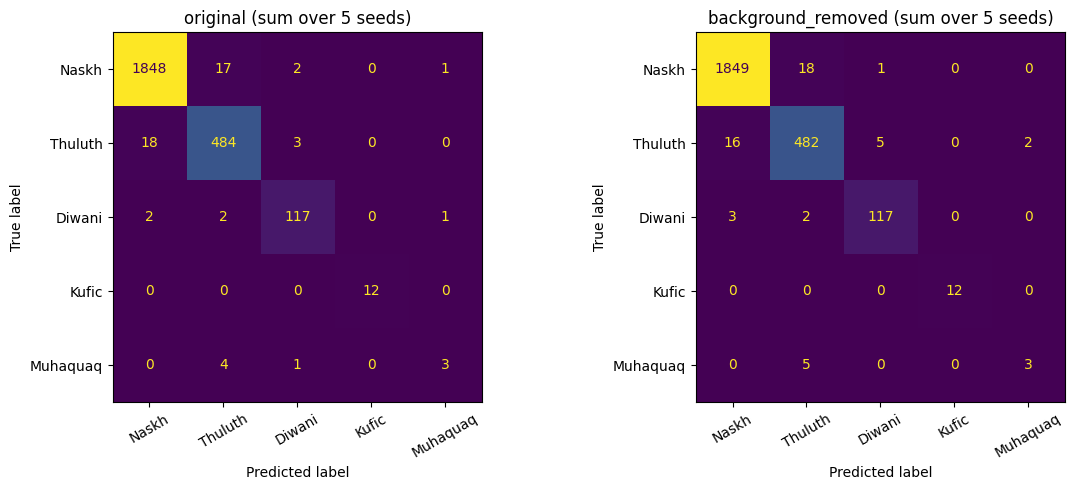

In [ ]:
df = pd.DataFrame([{"seed": r["seed"], "condition": r["name"],
                    "accuracy": accuracy_score(r["true"], r["pred"]),
                    "macro_F1": macro_f1(r["true"], r["pred"]),
                    "best_val_macro_F1": r["best_val_f1"],
                    "n_test": len(r["true"]), "train_min": round(r["train_min"], 1)} for r in all_results])
df.round(4).to_csv("results_per_seed.csv", index=False)

print("std and mean for each", len(SEEDS), "seeds ===")
summary = df.groupby("condition")[["accuracy", "macro_F1"]].agg(["mean", "std"]).round(3)
print(summary.to_string())
summary.to_csv("results_summary.csv")

print("\n difference for each seed (background_removed - original)")
piv_f1 = df.pivot(index="seed", columns="condition", values="macro_F1")
piv_acc = df.pivot(index="seed", columns="condition", values="accuracy")
paired = pd.DataFrame({"F1_original": piv_f1["original"],
                       "F1_bg_removed": piv_f1["background_removed"],
                       "F1_diff": piv_f1["background_removed"] - piv_f1["original"],
                       "Acc_diff": piv_acc["background_removed"] - piv_acc["original"]}).round(3)
print(paired.to_string())
print(f"mean Macro-F1 diff = {paired['F1_diff'].mean():.3f} (std {paired['F1_diff'].std():.3f}) | "
      f"background removal better in {(paired['F1_diff'] > 0).sum()} of {len(paired)} seeds, "
      f"worse in {(paired['F1_diff'] < 0).sum()}")

print("\nMean F1 per style")
names = ["original", "background_removed"]
pc = {n: np.mean([f1_score(r["true"], r["pred"], average=None, labels=LABELS, zero_division=0)
                  for r in all_results if r["name"] == n], axis=0) for n in names}
print(pd.DataFrame(pc, index=STYLES).round(3).to_string())

by = {(r["seed"], r["name"]): r for r in all_results}
changed = sum(int((by[(s, "original")]["pred"] != by[(s, "background_removed")]["pred"]).sum()) for s in SEEDS)
total = sum(len(by[(s, "original")]["pred"]) for s in SEEDS)
print(f"\nPredictions that changed between versions: {changed} out of {total} (total over all seeds)")

fig, ax = plt.subplots(1, 2, figsize=(12, 5))
for a, n in zip(ax, names):
    cm = sum(confusion_matrix(r["true"], r["pred"], labels=LABELS) for r in all_results if r["name"] == n)
    ConfusionMatrixDisplay(cm, display_labels=STYLES).plot(ax=a, colorbar=False, xticks_rotation=30)
    a.set_title(f"{n} (sum over {len(SEEDS)} seeds)")
plt.tight_layout(); plt.savefig("confusion_matrices.png", dpi=200); plt.show()

Training loss and validation macro-F1

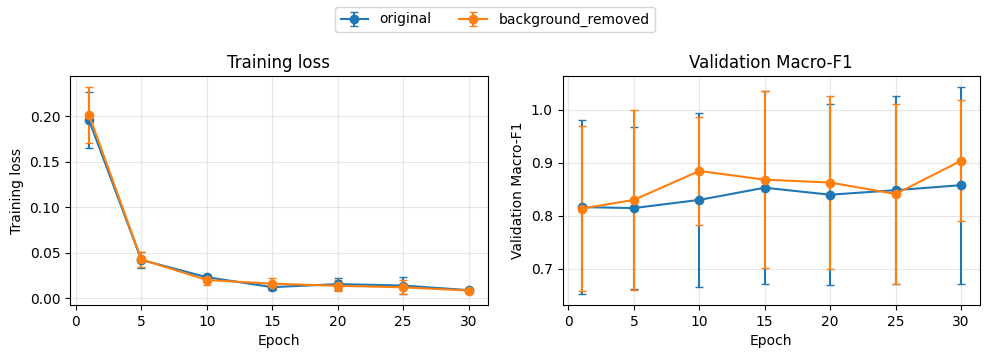

In [ ]:
import re
from google.colab import _message
nb = _message.blocking_request("get_ipynb")["ipynb"]
log = "".join("".join(o.get("text", "")) for c in nb["cells"] for o in c.get("outputs", []))

pat = r"\[seed (\d+) \| (\w+)\] epoch (\d+) \| train loss ([\d.]+) \| val macro-F1 ([\d.]+)"
curves = pd.DataFrame(re.findall(pat, log), columns=["seed", "condition", "epoch", "train_loss", "val_F1"])
curves = curves.astype({"epoch": int, "train_loss": float, "val_F1": float})
stats = curves.groupby(["condition", "epoch"])[["train_loss", "val_F1"]].agg(["mean", "std"])

fig, ax = plt.subplots(1, 2, figsize=(10, 3.6))
for n in names:
    s = stats.loc[n]
    for a, col in zip(ax, ["train_loss", "val_F1"]):
        a.errorbar(s.index, s[col]["mean"], yerr=s[col]["std"], marker="o", capsize=3, label=n)
ax[0].set(xlabel="Epoch", ylabel="Training loss", title="Training loss")
ax[1].set(xlabel="Epoch", ylabel="Validation Macro-F1", title="Validation Macro-F1")
for a in ax:
    a.grid(alpha=0.3)
fig.legend(*ax[0].get_legend_handles_labels(), loc="upper center", ncol=2)
plt.tight_layout(rect=[0, 0, 1, 0.9]); plt.savefig("training_curves.png", dpi=300); plt.show()

## 7) classification report

In [ ]:
print("Classification report per style (last seed)")
rep_txt = ""
for n in names:
    r = by[(SEEDS[-1], n)]
    rep = classification_report(r["true"], r["pred"], labels=LABELS, target_names=STYLES, zero_division=0)
    print(n); print(rep); rep_txt += f"{n}\n{rep}\n"
open("classification_reports.txt", "w").write(rep_txt)

print("=== Training Settings ===")
print("Hardware:", HARDWARE)
print("Dataset used:", len(allrows), "images | train/val/test =", len(tr), len(va), len(te))
print("Training time per model (min):", df.groupby("condition")["train_min"].mean().round(1).to_dict())
print("Epochs/batch/lr:", EPOCHS, BATCH, LR, "| seeds:", SEEDS)

Classification report per style (last seed)
original
              precision    recall  f1-score   support

       Naskh       0.99      0.99      0.99       373
     Thuluth       0.96      0.97      0.97       101
      Diwani       0.96      0.96      0.96        25
       Kufic       1.00      1.00      1.00         2
    Muhaquaq       0.00      0.00      0.00         2

    accuracy                           0.98       503
   macro avg       0.78      0.78      0.78       503
weighted avg       0.98      0.98      0.98       503

background_removed
              precision    recall  f1-score   support

       Naskh       0.99      0.99      0.99       373
     Thuluth       0.95      0.96      0.96       101
      Diwani       0.96      0.96      0.96        25
       Kufic       1.00      1.00      1.00         2
    Muhaquaq       0.00      0.00      0.00         2

    accuracy                           0.98       503
   macro avg       0.78      0.78      0.78       503
weigh

## 8) Library Versions

In [ ]:

import sys, platform, sklearn, torchvision, PIL, matplotlib
print("Library versions")
print("python", platform.python_version())
for m in [torch, torchvision, np, pd, sklearn, cv2, PIL, matplotlib]:
    print(f"{m.__name__}=={m.__version__}")
print("CUDA:", torch.version.cuda, "| cuDNN:", torch.backends.cudnn.version())

Library versions
python 3.13.16
torch==2.14.1+cu130
torchvision==0.29.1+cu130
numpy==2.4.6
pandas==2.2.3
sklearn==1.6.1
cv2==4.14.0
PIL==11.3.0
matplotlib==3.10.0
CUDA: 13.0 | cuDNN: 92800
